# Car Price Prediction Using Machine Learning

## 1. Introduction

The automobile industry is highly competitive, and car pricing plays an important role in determining a company's success in the market. The price of a car depends on several factors, such as engine specifications, fuel type, horsepower, mileage, dimensions, and other features.

A Chinese automobile company plans to enter the US automobile market by establishing a local manufacturing unit. To compete with established American and European automobile manufacturers, the company needs to understand the factors influencing car prices in the American market.

This project aims to develop a Machine Learning regression model that predicts car prices based on various independent variables available in the dataset.

Different regression algorithms will be implemented and evaluated to identify the most suitable model for predicting car prices. The project will also analyse the significant features affecting car prices and determine how well these features explain price variations.

The results will help the company understand the pricing patterns of the American automobile market and make informed decisions regarding car design, manufacturing strategies, and pricing.


## 2. Importing Libraries and Loading the Dataset

### 2.1 Importing Libraries

Python libraries are imported to perform data manipulation, numerical computations, data visualisation, and machine learning operations.

### 2.2 Loading the Dataset

The car price dataset is loaded into a Pandas DataFrame using the `read_csv()` function.

A DataFrame is a two-dimensional tabular data structure consisting of rows and columns. It allows us to efficiently analyse and manipulate the dataset.


In [1]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('CarPrice_Assignment.csv')

## 2.3 Initial Dataset Inspection

After loading the dataset, an initial inspection is performed to understand its structure, size, data types, and statistical properties.

This step helps identify potential data quality issues and determine the preprocessing operations required before applying machine learning algorithms.

The following aspects are examined:

* First few records of the dataset.
* Number of rows and columns.
* Column names and data types.
* Statistical summary of numerical features.
* Missing values.
* Duplicate records.


In [3]:
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [4]:
df.shape

(205, 26)

In [5]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [6]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [7]:
df.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

###  Initial Dataset Observations

The dataset consists of 205 rows and 26 columns.

The initial inspection reveals the following:

* The dataset contains 205 car records.
* There are 26 columns, including independent variables and the target variable.
* The target variable for prediction is `price`.
* The dataset contains both numerical and categorical features.
* No missing values were identified.
* No duplicate records were found.

### Initial Conclusion

The dataset is structurally complete, with no missing values or duplicate records. However, further preprocessing is required to handle categorical variables, examine outliers, identify irrelevant features, and prepare the data for regression algorithms.


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the characteristics of the dataset, identify patterns, detect outliers, and analyse relationships between different variables.

EDA helps us understand how different car specifications influence the price of a vehicle. It also helps in identifying important features that may contribute to building an accurate machine learning model.

EDA is performed in three stages:

1. **Univariate Analysis:** Analysing individual variables to understand their distributions and characteristics.
2. **Bivariate Analysis:** Analysing the relationship between two variables to identify patterns and associations.
3. **Multivariate Analysis:** Analysing relationships among multiple variables to understand their combined influence.


### 3.1 Univariate Analysis

Univariate analysis is the process of analysing one variable at a time to understand its distribution, frequency, and statistical characteristics.

In this project, univariate analysis is performed to understand the individual characteristics of numerical and categorical features in the car price dataset.

For numerical variables, histograms and boxplots can be used. For categorical variables, count plots can be used.


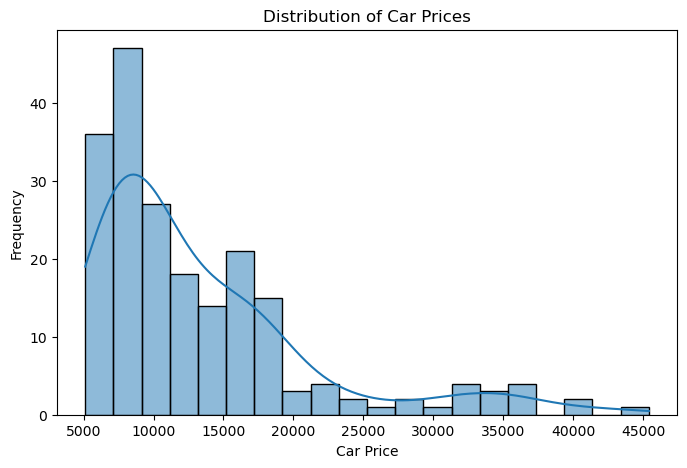

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df['price'],bins=20,kde=True)
plt.title('Distribution of Car Prices')
plt.xlabel('Car Price')
plt.ylabel('Frequency')
plt.show()

#### 3.1.1 Distribution of Car Prices

A histogram is used to visualize the frequency distribution of the target variable, `price`.

**Observations:**

* The distribution of car prices is positively skewed (right-skewed).
* Most cars are concentrated in the lower price ranges.
* The frequency of cars decreases as the price increases.
* A relatively smaller number of cars belong to higher price ranges.

**Inference:**

The car price distribution is not symmetrical and exhibits positive skewness. This indicates that the dataset contains more affordable cars compared to expensive cars.


#### 3.1.2 Distribution of Horsepower

Horsepower represents the power produced by a car's engine. Analysing its distribution helps us understand how engine power varies across the cars in the dataset.


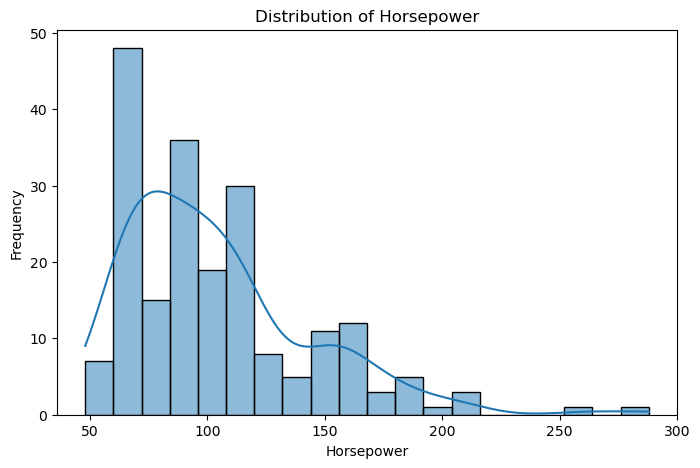

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df['horsepower'],bins=20,kde=True)
plt.title('Distribution of Horsepower')
plt.xlabel('Horsepower')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The horsepower distribution is positively skewed (right-skewed).
* Most cars have horsepower values between approximately 50 and 100.
* The frequency of cars decreases as horsepower increases.
* Only a few cars have higher horsepower values.

**Inference:**

Most cars in the dataset have relatively low to moderate horsepower, while only a few cars have high engine power.


#### 3.1.3 Distribution of Engine Size

Engine size represents the volume of an engine's cylinders and is generally measured in cubic centimetres (cc). Analysing its distribution helps us understand the variation in engine capacity among the cars in the dataset.


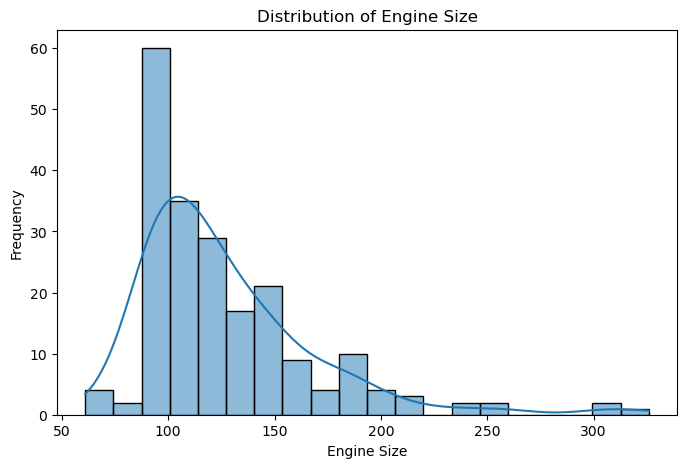

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['enginesize'],bins=20,kde=True)
plt.title('Distribution of Engine Size')
plt.xlabel('Engine Size')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The distribution of engine size is positively skewed (right-skewed).
* Most cars have engine sizes between approximately 90 and 150 cc.
* The frequency of cars decreases as engine size increases.
* Only a few cars have larger engine sizes.

**Inference:**

Most cars in the dataset have relatively small to moderate engine capacities, while only a few cars have larger engines.


#### 3.1.4 Distribution of Curb Weight

Curb weight refers to the total weight of a vehicle without passengers or cargo, but with all standard equipment and necessary fluids.

Analysing its distribution helps us understand how vehicle weight varies across the cars in the dataset.


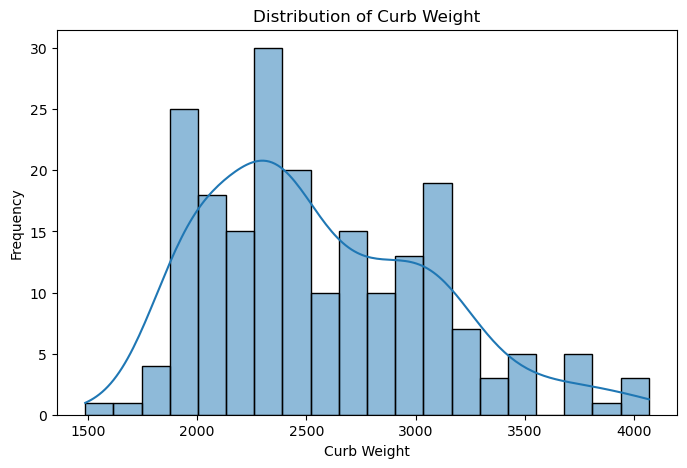

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(df['curbweight'],bins=20,kde=True)
plt.title('Distribution of Curb Weight')
plt.xlabel('Curb Weight')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The curb weight distribution is positively skewed (right-skewed).
* Most cars have curb weights between approximately 2,000 and 2,500 pounds.
* The frequency of cars decreases as curb weight increases.
* Only a few cars have higher curb weights.

**Inference:**

Most cars in the dataset have a relatively moderate curb weight, while only a few vehicles are heavier.


#### 3.1.5 Distribution of City MPG

City MPG (Miles Per Gallon) represents the number of miles a car can travel using one gallon of fuel in city driving conditions.

Analysing its distribution helps us understand the fuel efficiency of different cars in urban driving conditions.


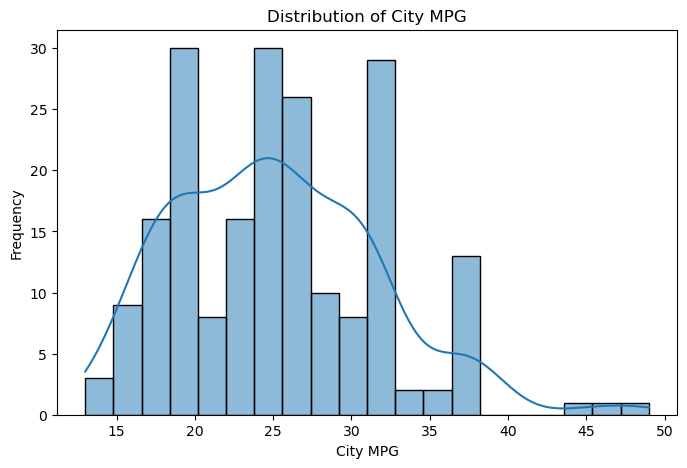

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df['citympg'],bins=20,kde=True)
plt.title('Distribution of City MPG')
plt.xlabel('City MPG')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The city MPG distribution is positively skewed (right-skewed).
* Most cars have city MPG values between approximately 19 and 32.
* The frequency of cars decreases towards higher MPG values.
* Only a few cars have higher city fuel efficiency.

**Inference:**

Most cars have moderate fuel efficiency in city driving conditions, while only a few cars achieve higher mileage.


#### 3.1.6 Distribution of Highway MPG

Highway MPG (Miles Per Gallon) represents the number of miles a car can travel using one gallon of fuel under highway driving conditions.

Analysing its distribution helps us understand and compare the fuel efficiency of different cars during highway driving.


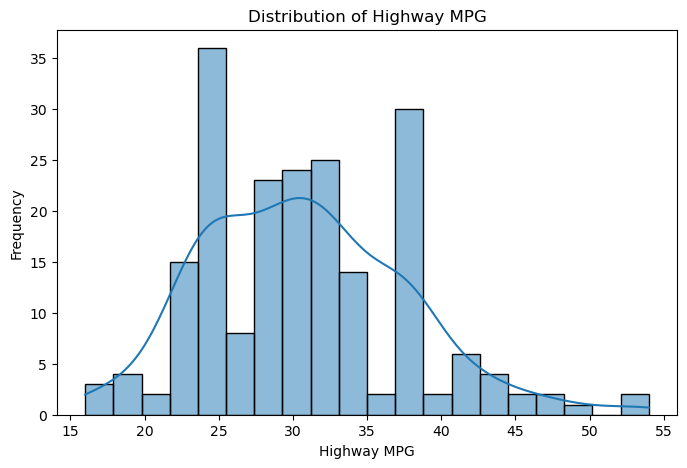

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(df['highwaympg'],bins=20,kde=True)
plt.title('Distribution of Highway MPG')
plt.xlabel('Highway MPG')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The highway MPG distribution is positively skewed (right-skewed).
* Most cars have highway MPG values between approximately 24 and 38.
* The frequency of cars generally decreases towards higher MPG values.
* Only a few cars have higher highway fuel efficiency.

**Inference:**

Most cars have moderate highway fuel efficiency, while a smaller number of cars achieve higher mileage.


#### 3.1.7 Distribution of Fuel Type

Fuel type represents the type of fuel used by a car. In this dataset, the two fuel categories are petrol (gas) and diesel.

A bar chart is used to visualize the frequency of each fuel type and understand which type is more commonly used among the cars in the dataset.


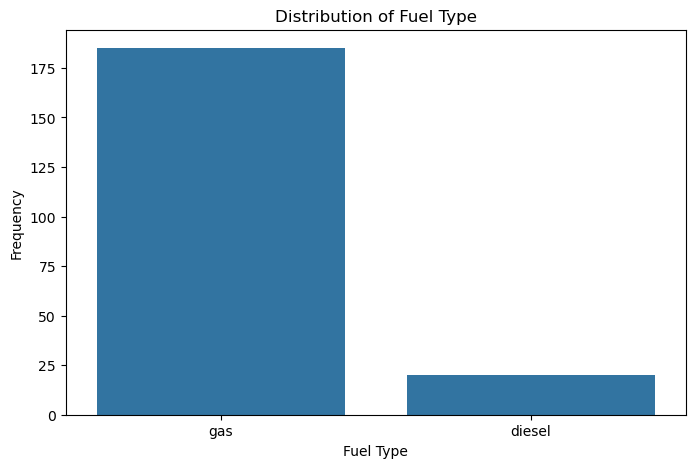

In [16]:
plt.figure(figsize=(8,5))
sns.countplot(x =df['fueltype'])
plt.title('Distribution of Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains two fuel types: gas and diesel.
* Gas-powered cars have a higher frequency than diesel-powered cars.
* Diesel-powered cars are comparatively fewer in the dataset.

**Inference:**

Most cars in the dataset use gas as their fuel type, indicating that gas-powered vehicles dominate the dataset.


#### 3.1.8 Distribution of Aspiration Type

Aspiration refers to the method by which air enters the engine for combustion. In this dataset, the two aspiration types are standard and turbo.

A bar chart is used to visualize the frequency of each aspiration type and understand which type is more commonly used among the cars.


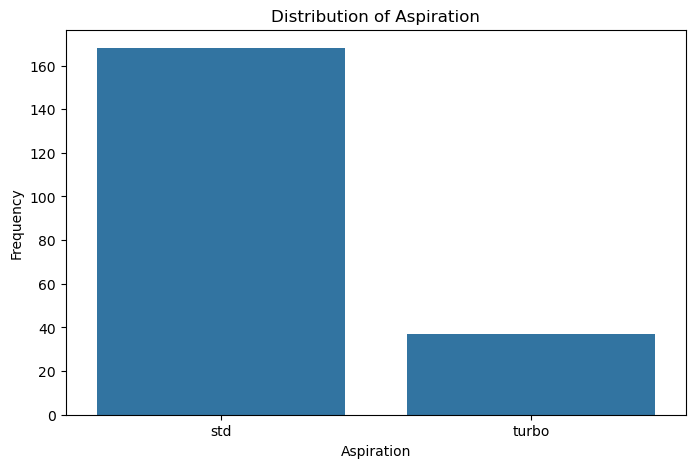

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['aspiration'])
plt.title('Distribution of Aspiration')
plt.xlabel('Aspiration')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains two aspiration types: standard and turbo.
* Standard aspiration cars have a higher frequency than turbo cars.
* Turbo aspiration cars are comparatively fewer in the dataset.

**Inference:**

Most cars in the dataset use the standard aspiration system, indicating that standard aspiration vehicles dominate the dataset.


#### 3.1.9 Distribution of Car Body Type

Car body type refers to the overall shape and design of a vehicle. The dataset contains different body types, such as sedan, hatchback, wagon, hardtop, and convertible.

A bar chart is used to visualize the frequency of each car body type and identify the most common body style in the dataset.


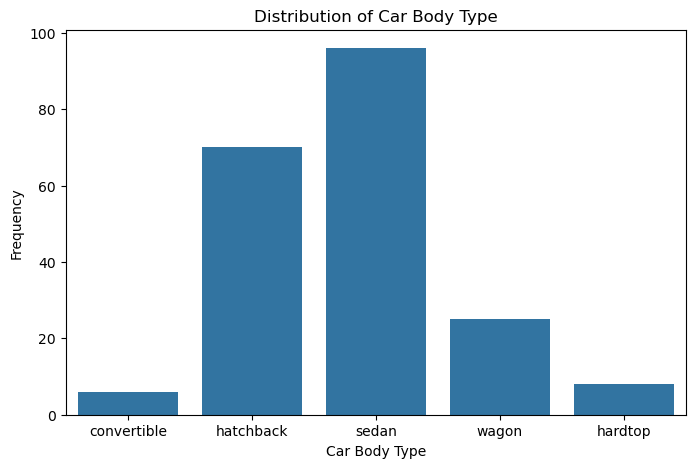

In [18]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['carbody'])
plt.title('Distribution of Car Body Type')
plt.xlabel('Car Body Type')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains five car body types: sedan, hatchback, wagon, hardtop, and convertible.
* Sedan has the highest frequency among all car body types.
* Convertible and hardtop cars are comparatively fewer.

**Inference:**

Sedan is the dominant car body type in the dataset, indicating that most vehicles belong to the sedan category.


#### 3.1.10 Distribution of Drive Wheel Type

Drive wheel type refers to the wheels that receive power from the engine to move the vehicle.

The dataset contains three drive wheel types:

* **FWD:** Front-Wheel Drive
* **RWD:** Rear-Wheel Drive
* **4WD:** Four-Wheel Drive

A bar chart is used to visualize the frequency of each drive wheel type and identify the most common drivetrain configuration among the cars.


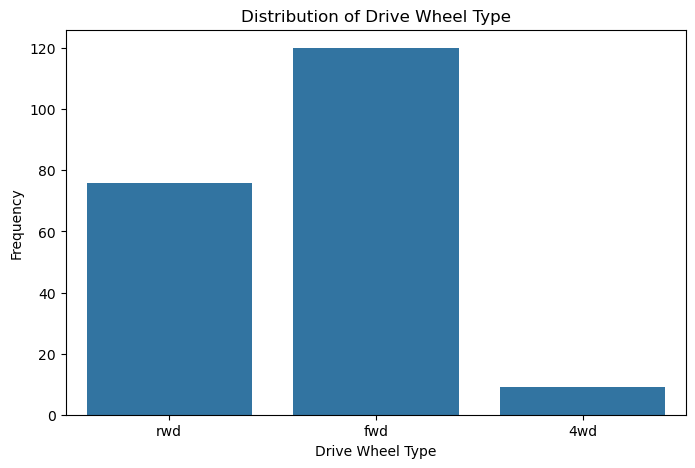

In [19]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['drivewheel'])
plt.title('Distribution of Drive Wheel Type')
plt.xlabel('Drive Wheel Type')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains three drive wheel types: FWD, RWD, and 4WD.
* FWD cars have the highest frequency.
* RWD cars are also present in considerable numbers.
* 4WD cars are comparatively fewer.

**Inference:**

Front-Wheel Drive (FWD) is the most common drivetrain configuration among the cars in the dataset.


#### 3.1.11 Distribution of Engine Location

Engine location refers to the position where the engine is placed in a vehicle. In this dataset, there are two engine location categories: front and rear.

A bar chart is used to visualize the frequency of each engine location and identify the most common engine placement among the cars.


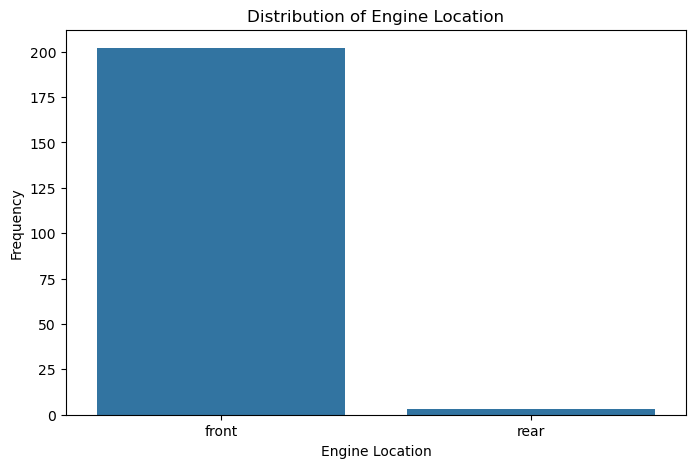

In [20]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['enginelocation'])
plt.title('Distribution of Engine Location')
plt.xlabel('Engine Location')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains two engine locations: front and rear.
* Front-engine cars have a significantly higher frequency than rear-engine cars.
* Rear-engine cars are very few in the dataset.

**Inference:**

Most cars in the dataset have a front-engine configuration, indicating that front-engine placement is the dominant design.


#### 3.1.12 Distribution of Engine Type

Engine type refers to the design and configuration of an engine's valve mechanism. The dataset contains different engine types, such as DOHC, OHC, OHCV, and others.

A bar chart is used to visualize the frequency of each engine type and identify the most common engine configuration among the cars in the dataset.


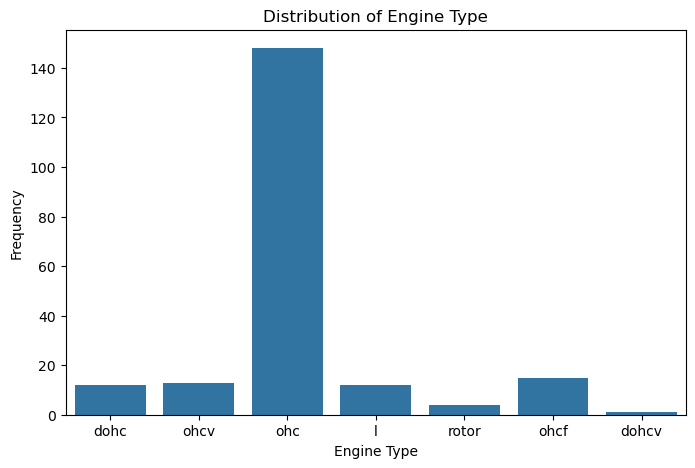

In [21]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['enginetype'])
plt.title('Distribution of Engine Type')
plt.xlabel('Engine Type')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains different engine types, including OHC, DOHC, OHCV, DOHCV, and L.
* OHC has the highest frequency among the engine types.
* DOHCV has the lowest frequency.
* Other engine types are present in varying numbers.

**Inference:**

OHC is the most common engine type in the dataset, while DOHCV is rarely used among the cars.


#### 3.1.13 Distribution of Cylinder Number

Cylinder number refers to the number of cylinders present in a car's engine. Cylinders play an important role in generating engine power.

The dataset contains different cylinder configurations, such as two, three, four, five, six, eight, and twelve cylinders.

A bar chart is used to visualize the frequency of each cylinder configuration and identify the most common number of cylinders among the cars.


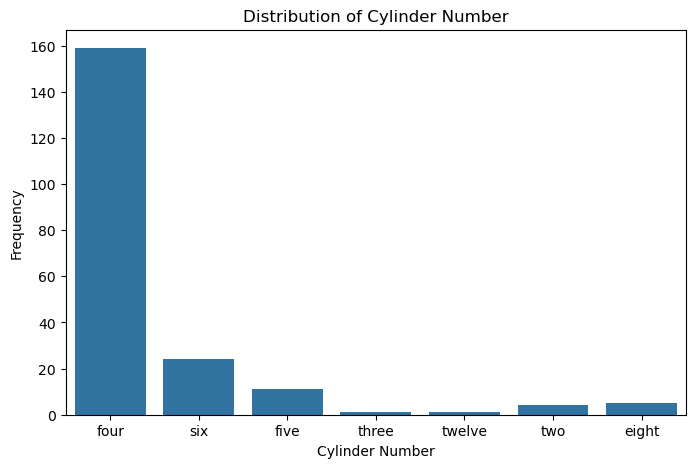

In [22]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['cylindernumber'])
plt.title('Distribution of Cylinder Number')
plt.xlabel('Cylinder Number')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains cars with different cylinder configurations.
* Four-cylinder engines have the highest frequency.
* Three-cylinder engines have the lowest frequency.
* Other cylinder configurations are present in smaller numbers.

**Inference:**

Most cars in the dataset use four-cylinder engines, indicating that this is the most common engine configuration.


#### 3.1.14 Distribution of Fuel System

The fuel system is responsible for delivering fuel to the engine for combustion. Different fuel systems are used in vehicles to control fuel delivery and engine performance.

The dataset contains different fuel system types, such as MPFI, 2BBL, 1BBL, and others.

A bar chart is used to visualize the frequency of each fuel system type and identify the most commonly used fuel system among the cars.


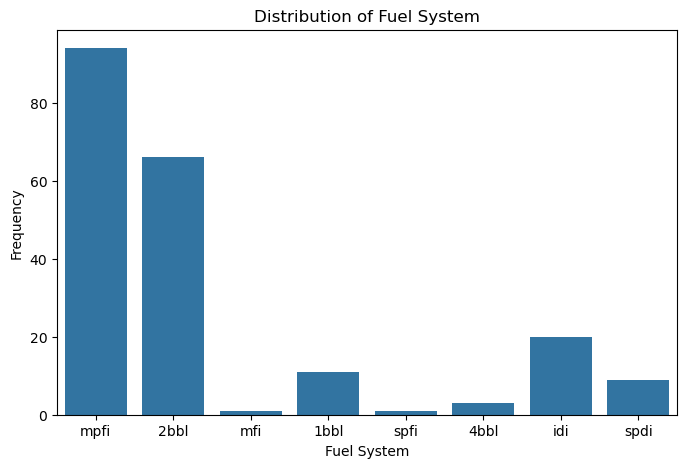

In [23]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['fuelsystem'])
plt.title('Distribution of Fuel System')
plt.xlabel('Fuel System')
plt.ylabel('Frequency')
plt.show()

**Observations:**

* The dataset contains different fuel system types, including MPFI, 2BBL, 1BBL, and MFI.
* MPFI has the highest frequency among the fuel system types.
* MFI has the lowest frequency.
* Other fuel systems are present in varying numbers.

**Inference:**

MPFI is the most commonly used fuel system in the dataset, while MFI is the least common.


#### 3.1.15 Distribution of Remaining Numerical Features

In this step, the distributions of the remaining numerical features are visualized using histograms. Multiple histograms are arranged in a 3 × 3 grid to make it easier to compare the distributions of different features.

The `histplot()` function from Seaborn is used with 20 bins and KDE curves. These visualizations help identify the shape of each distribution, data concentration, skewness, and variations among the numerical features.


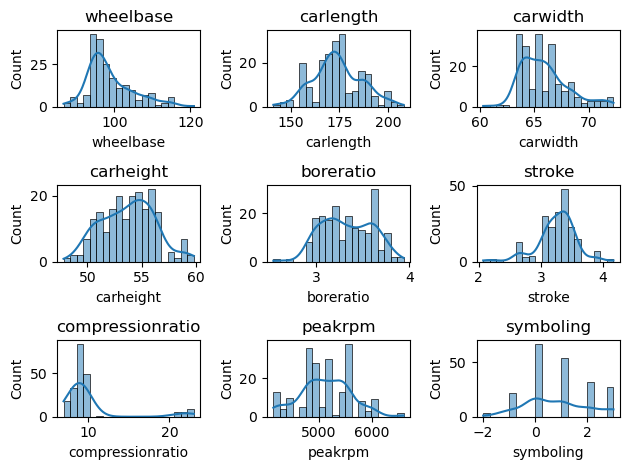

In [24]:
col=['wheelbase','carlength','carwidth','carheight','boreratio','stroke','compressionratio','peakrpm','symboling']
for i in range(len(col)):
    plt.subplot(3,3,i+1)
    sns.histplot(df[col[i]],bins=20,kde=True)
    plt.title(col[i])
plt.tight_layout()
plt.show()

**Conclusion:**

The histograms show that different numerical features have different distribution patterns. Some features are approximately normally distributed, while others show left or right skewness. The visualizations also reveal variations in data concentration and the presence of discrete numerical values, such as symboling.

This analysis provides a better understanding of the numerical features and helps identify distribution patterns that may be important during data preprocessing and model development.


#### 3.1.16 Distribution of Door Number

The `doornumber` feature represents the number of doors in each car. It is a categorical variable with two categories: **two** and **four**.

A count plot is used to visualize the frequency of each category. This helps identify which door configuration is more common in the dataset.


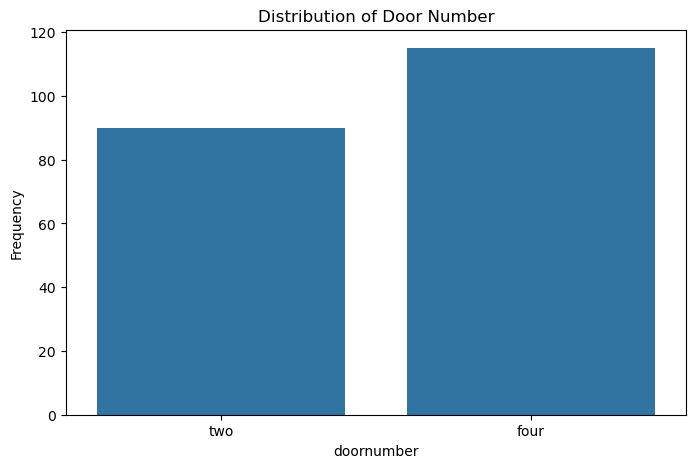

In [25]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['doornumber'])
plt.title('Distribution of Door Number')
plt.xlabel('doornumber')
plt.ylabel('Frequency')
plt.show()

**Observation:**

The count plot shows that four-door cars have a higher frequency than two-door cars in the dataset. Therefore, four-door cars are more common than two-door cars.


## 3.2 Bivariate Analysis

Bivariate analysis is used to examine the relationship between two variables in a dataset. It helps identify patterns, trends, correlations, and how one variable changes in relation to another.

In this project, bivariate analysis is performed to understand how different numerical and categorical features influence the price of cars.

Different visualizations, such as scatter plots and box plots, are used to study the relationships between car prices and other features. Multiple plots are arranged using subplots to make comparison easier.


#### 3.2.1 Relationship Between Numerical Features and Car Price

In this step, bivariate analysis is performed to examine the relationship between numerical features and the target variable, `price`.

Scatter plots are used to visualize how changes in different numerical features are associated with changes in car prices. Eight numerical features, including engine size, horsepower, curbweight, car width, mileage, wheelbase, and compression ratio, are selected for this analysis.

Multiple scatter plots are arranged in a 3 × 3 subplot grid to compare the relationships easily. This analysis helps identify positive and negative relationships, patterns, and possible outliers that may influence car prices.


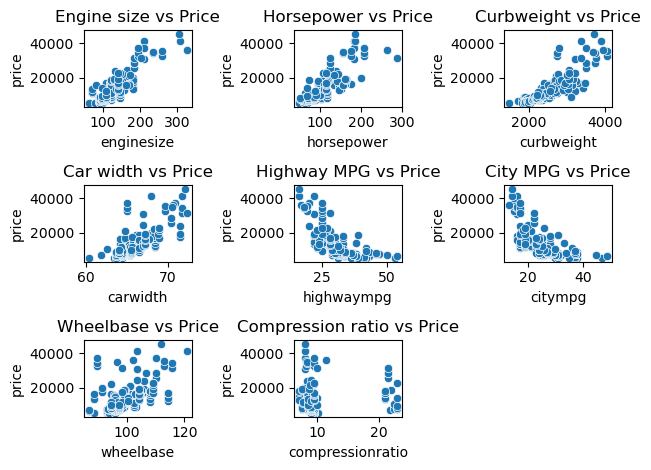

In [26]:
numeric_cols=['enginesize','horsepower','curbweight','carwidth','highwaympg','citympg','wheelbase','compressionratio']
titles=['Engine size vs Price','Horsepower vs Price','Curbweight vs Price','Car width vs Price','Highway MPG vs Price','City MPG vs Price','Wheelbase vs Price','Compression ratio vs Price']
for i in range(len(numeric_cols)):
    plt.subplot(3,3,i+1)
    sns.scatterplot(df,x=numeric_cols[i],y='price')
    plt.title(titles[i])
plt.tight_layout()
plt.show()

**Conclusion:**

The scatter plots reveal different relationships between numerical features and car prices. Engine size, horsepower, curbweight, car width and wheelbase show positive relationships with price. City MPG and highway MPG show negative relationships with price. Compression ratio does not show a clear linear relationship.

Overall, this analysis indicates that engine size, horsepower and curbweight may be important features influencing car prices. These relationships will be examined further during correlation analysis and model development.


#### 3.2.2 Relationship Between Categorical Features and Car Price

In this step, bivariate analysis is performed to examine how different categorical features are related to car prices.

Box plots are used to compare the distribution of car prices across different categories. They help identify the median price, data spread, variation, and potential outliers within each category.

Features such as fuel type, aspiration, car body, drive wheel, engine location, engine type, cylinder number, fuel system, and door number are considered for this analysis.

Multiple box plots are arranged using subplots to make comparisons easier and to identify which categorical features may have an influence on car prices.


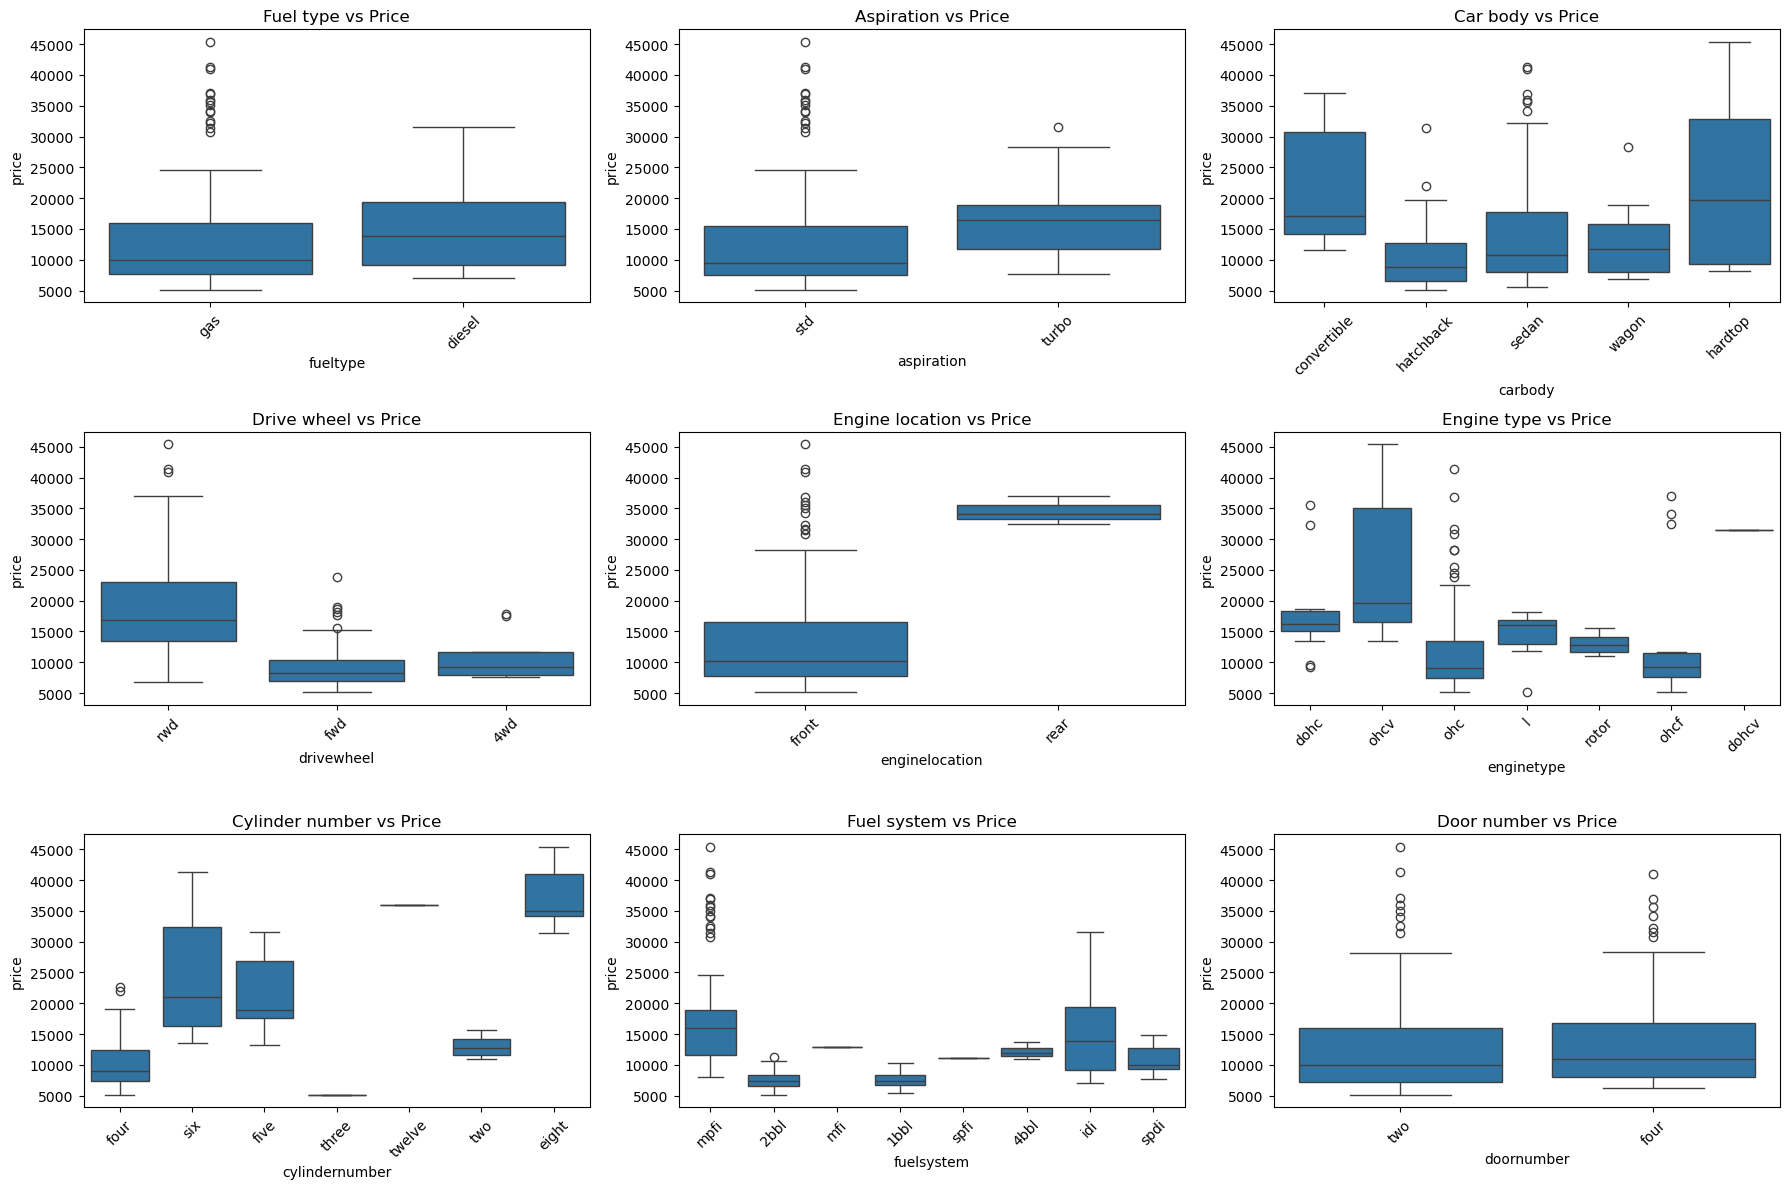

In [27]:
categorical_cols=['fueltype',
                  'aspiration',
                  'carbody',
                  'drivewheel',
                  'enginelocation',
                  'enginetype',
                  'cylindernumber',
                  'fuelsystem',
                  'doornumber']
categorical_titles=['Fuel type vs Price',
                    'Aspiration vs Price',
                    'Car body vs Price',	
                    'Drive wheel vs Price',
                    'Engine location vs Price',
                    'Engine type vs Price',	
                    'Cylinder number vs Price',
                    'Fuel system vs Price',
                    'Door number vs Price']
plt.figure(figsize=(18, 12))          
for i in range(len(categorical_cols)):
    plt.subplot(3,3,i+1)
    sns.boxplot(df,x=categorical_cols[i],y='price')
    plt.title(categorical_titles[i])
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Conclusion:**

The box plots show that car prices vary across different categories of categorical features.

* **Fuel type:** Diesel cars generally have a higher median price than gas cars.
* **Aspiration:** Turbo cars have a higher median price than standard aspiration cars.
* **Car body:** Hardtop and convertible cars show relatively higher median prices, while hatchback cars have lower median prices.
* **Drive wheel:** Rear-wheel-drive cars have higher median prices than front-wheel-drive and four-wheel-drive cars.
* **Engine location:** Rear-engine cars have significantly higher median prices than front-engine cars.
* **Engine type:** Prices vary across different engine types, with some categories showing higher median prices.
* **Cylinder number:** Cars with eight and twelve cylinders generally have higher prices than cars with fewer cylinders.
* **Fuel system:** Price distributions vary across different fuel systems, with MPFI and IDI showing considerable variation.
* **Door number:** Two-door and four-door cars have relatively similar median prices.

Several box plots also show outliers, indicating the presence of cars with unusually high or low prices compared with other cars in the same category.

Overall, this analysis suggests that categorical features such as aspiration, car body, drive wheel, engine location, and cylinder number may be useful for predicting car prices.


## 3.3 Multivariate Analysis

Multivariate analysis is performed to examine relationships among multiple variables in the dataset. It helps understand how different features interact with each other and how they are associated with the target variable, price.

In this project, correlation analysis is used to study the relationships between numerical features. A correlation heatmap is used to visualize the correlation matrix, making it easier to identify strongly correlated features and understand their relationships with car prices.


#### 3.3.1 Correlation Analysis

Correlation analysis is used to measure the strength and direction of the relationship between numerical features in a dataset.

The correlation coefficient ranges from -1 to +1. A positive correlation indicates that two variables tend to increase together, while a negative correlation indicates that one variable tends to decrease as the other increases. A value close to zero indicates a weak linear relationship.

In this project, a correlation matrix is calculated using numerical features and visualized using a heatmap. This helps identify features that are strongly related to the target variable, price, and detect possible multicollinearity among independent variables.


In [28]:
import numpy as np

<Axes: >

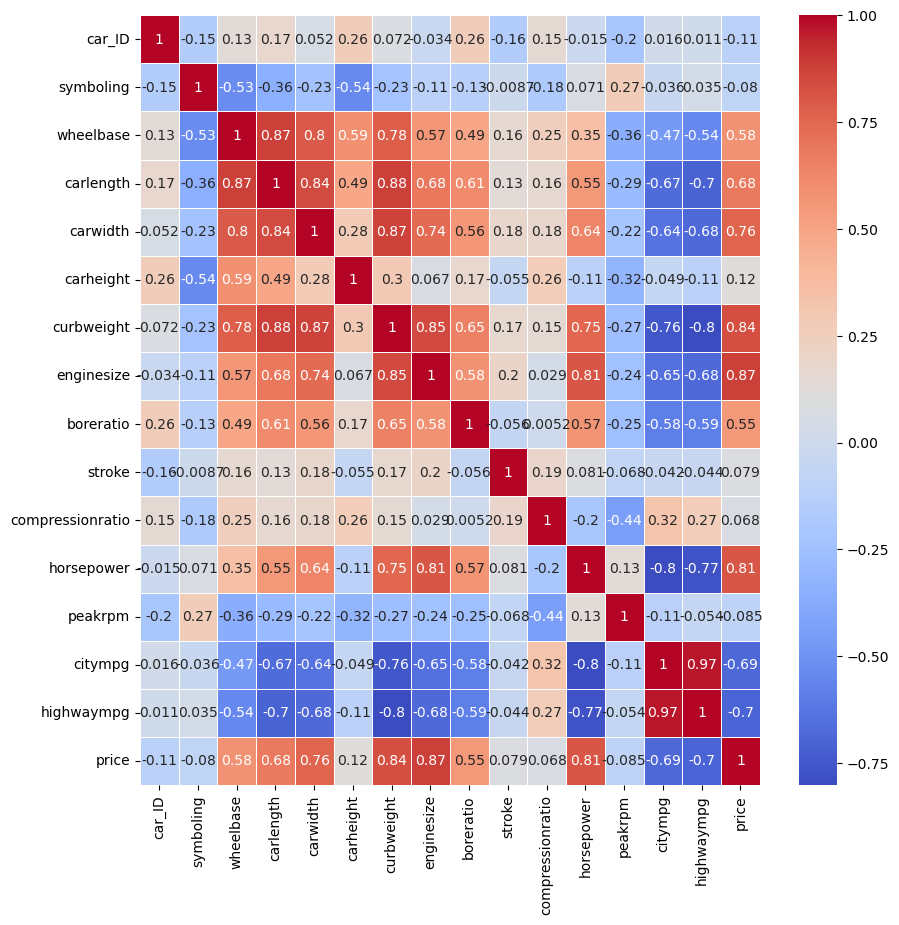

In [29]:
num_cols=df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10,10))
sns.heatmap(num_cols,annot=True,cmap='coolwarm',linewidths=0.5)

###3.3.1.1 Observations and Conclusion

The correlation heatmap was used to understand the relationships between numerical features and the target variable, price.

The following observations were made:

* Engine size showed the strongest positive correlation with price (0.87).
* Curb weight (0.84) and horsepower (0.81) also showed strong positive correlations with price.
* Highway MPG (-0.70) and City MPG (-0.69) showed negative correlations with price.
* City MPG and Highway MPG had a very strong positive correlation (0.97), indicating possible multicollinearity.
* Compression ratio showed a very weak correlation with price.

**Conclusion:**

The correlation analysis indicates that engine size, curb weight, and horsepower are strongly associated with car prices. It also identifies highly correlated independent features, such as City MPG and Highway MPG, which may require further investigation during feature selection and model building.


### 4.1 Separating Features and Target Variable

The target variable is `price`, which represents the price of each car. The remaining relevant columns are considered independent features.

The `car_ID` column is removed because it is only an identifier and does not provide meaningful information for predicting car prices.


In [30]:

df = df.drop('car_ID', axis=1)

X = df.drop('price', axis=1)
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (205, 24)
Target shape: (205,)


### 4.2 Identifying Numerical and Categorical Features

The dataset contains both numerical and categorical variables.

Numerical features represent measurable quantities, whereas categorical features represent different groups or categories.

Identifying these feature types is important because they require different preprocessing techniques before applying machine learning algorithms.


In [31]:

num_cols = X.select_dtypes(include=np.number).columns.tolist()

cat_cols = X.select_dtypes(include='object').columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Categorical columns: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


### 4.3 Categorical Encoding

Machine learning regression algorithms require numerical input. Therefore, categorical variables must be converted into numerical representations.

One-Hot Encoding is used to convert categorical features into binary columns. This technique is suitable for nominal categorical variables because it does not introduce an artificial order between categories.


In [32]:
# Apply One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print("Shape after encoding:", X_encoded.shape)

Shape after encoding: (205, 189)


### 4.4 Train-Test Split

The dataset is divided into training and testing sets.

* Training data (80%): Used to train the machine learning models.
* Testing data (20%): Used to evaluate the performance of the trained models.

This helps determine how well the models perform on unseen data.


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (164, 189)
Testing data: (41, 189)


### 4.5 Feature Scaling

Feature scaling is the process of bringing numerical features into a similar range.

StandardScaler is used to standardize the features by removing the mean and scaling them to unit variance.

Feature scaling is particularly important for algorithms such as Support Vector Regression because they are sensitive to differences in feature scales.


In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 5. Model Building and Evaluation

After completing data preprocessing, different machine learning regression algorithms are applied to predict car prices.

Five regression models are selected for this project:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. Support Vector Regressor (SVR)

The models are trained using the training dataset and evaluated using the testing dataset to compare their prediction performance.


### 5.1 Importing Machine Learning Algorithms

The required regression algorithms and evaluation metrics are imported from the Scikit-learn library.

These algorithms are used to train predictive models, while evaluation metrics help measure and compare their performance.


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

### 5.2 Model Training

The five selected regression algorithms are trained using the training dataset.

Each model learns the relationship between the input features and the target variable, price.

The trained models are then used to predict car prices using the testing dataset.


In [36]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

results = []

for name, model in models.items():

    if name == 'SVR':
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)

    results.append({
        'Model': name,
        'R2 Score': r2,
        'MSE': mse,
        'MAE': mae
    })

results_df = pd.DataFrame(results)
print(results_df)

               Model  R2 Score           MSE          MAE
0  Linear Regression  0.473715  4.154703e+07  4177.295631
1      Decision Tree  0.855898  1.137602e+07  2200.142268
2      Random Forest  0.953457  3.674318e+06  1365.352512
3  Gradient Boosting  0.930597  5.478929e+06  1700.986585
4                SVR -0.101709  8.697331e+07  5705.033285


### 5.3 Model Evaluation

The performance of the regression models is evaluated using the following metrics:

**1. R² Score:** Measures how well the model explains the variation in car prices. A higher R² score indicates better performance.

**2. Mean Squared Error (MSE):** Measures the average squared difference between actual and predicted prices. A lower MSE indicates better performance.

**3. Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted prices. A lower MAE indicates better performance.

These metrics are used to compare the five models and identify the most suitable model for car price prediction.


### 5.4 Model Performance Visualization

A bar chart is created to visualize and compare the R² scores of the five regression models.

This visualization makes it easier to identify which model performs better in predicting car prices.


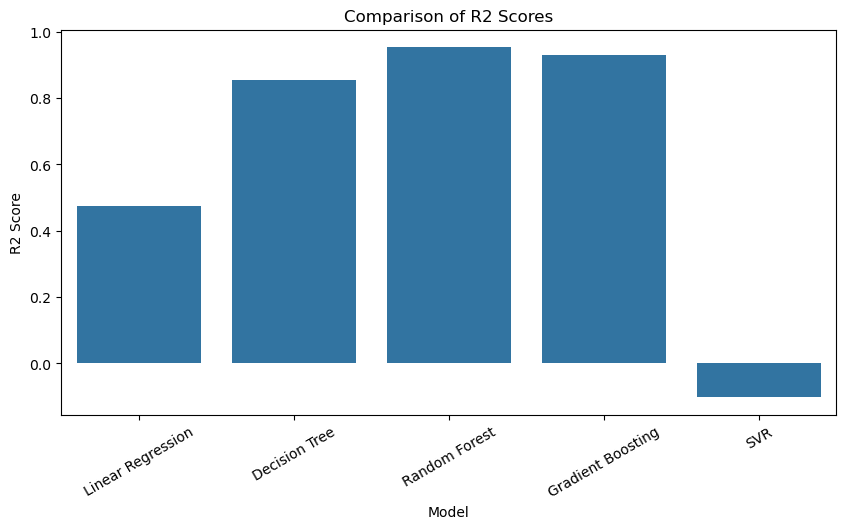

In [37]:
plt.figure(figsize=(10,5))
sns.barplot(data=results_df, x='Model', y='R2 Score')
plt.title('Comparison of R2 Scores')
plt.xticks(rotation=30)
plt.show()

### 5.5 Observations and Model Comparison

After training and evaluating the five regression models, the following observations were made:

* Random Forest Regressor achieved the highest R² score of 0.953, indicating that it explains approximately 95.35% of the variation in car prices.
* Random Forest also obtained the lowest MSE (3,674,318) and MAE (1,365.35), demonstrating better prediction accuracy than the other models.
* Gradient Boosting Regressor achieved the second-highest R² score of 0.931.
* Decision Tree Regressor achieved an R² score of 0.856.
* Linear Regression achieved a comparatively lower R² score of 0.474.
* Support Vector Regressor (SVR) performed the worst, with a negative R² score of -0.102.

**Conclusion:**

Based on the R² score, MSE, and MAE, Random Forest Regressor was identified as the best-performing model among the five algorithms.

Further feature importance analysis and hyperparameter tuning will be performed to investigate possible improvements in model performance.


## 6. Feature Importance Analysis

Feature importance analysis is used to identify the input features that contribute most to the predictions made by a machine learning model.

In this project, feature importance is obtained using the Random Forest Regressor, which was identified as the best-performing model during the initial evaluation.

This analysis helps understand which car characteristics have the greatest predictive influence on car prices.


In [38]:
# Calculate feature importance
rf_model = models['Random Forest']

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance)

                         Feature  Importance
6                     enginesize    0.540808
5                     curbweight    0.294927
13                    highwaympg    0.043387
10                    horsepower    0.038275
3                       carwidth    0.013358
..                           ...         ...
142     CarName_vokswagen rabbit    0.000000
91           CarName_nissan note    0.000000
118          CarName_subaru baja    0.000000
55   CarName_honda civic 1500 gl    0.000000
147    CarName_volkswagen rabbit    0.000000

[189 rows x 2 columns]


### Visualization of Feature Importance

A bar chart is used to visualize the importance of each feature.

The features are arranged in descending order of importance, making it easier to identify the most influential variables in predicting car prices.


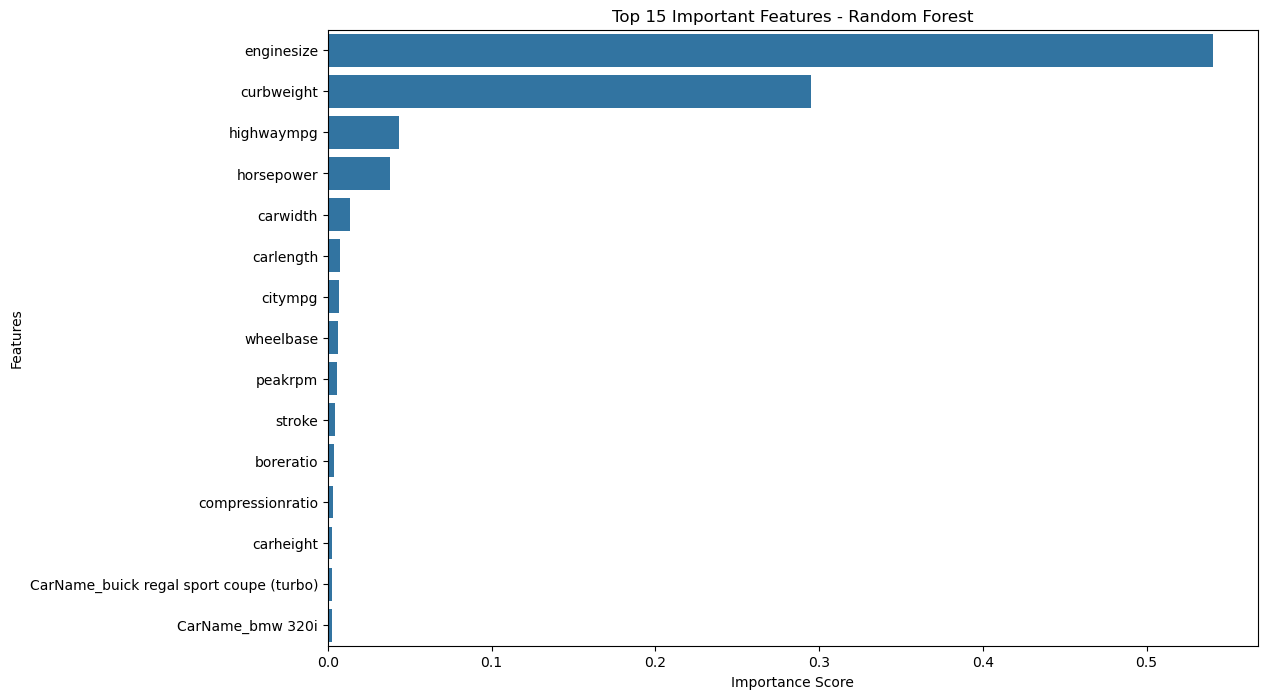

In [39]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

### Observations and Conclusion

The feature importance analysis using Random Forest Regressor produced the following observations:

* Engine size was identified as the most important feature, with an importance score of 0.5408.
* Curb weight was the second most important feature, with an importance score of 0.2949.
* Highway MPG and horsepower also contributed to the prediction of car prices.
* Other features, such as car width, car length, and city MPG, showed comparatively lower importance.
* Some features had very low or zero importance in the trained model.

**Conclusion:**

The analysis indicates that engine size and curb weight are the two most influential features in predicting car prices using the Random Forest model. These findings help identify the car characteristics that contribute most to the model's predictions.


## 7. Hyperparameter Tuning

Hyperparameter tuning is the process of finding the best configuration of a machine learning model to improve its performance.

In this project, Random Forest Regressor is selected for hyperparameter tuning because it achieved the best performance during the initial model comparison.

GridSearchCV is used to test different combinations of hyperparameter values and identify the combination that produces the best cross-validation performance.


In [40]:
from sklearn.model_selection import GridSearchCV

### Defining Hyperparameters

The following Random Forest hyperparameters are selected for tuning:

* `n_estimators`: Number of decision trees in the forest.
* `max_depth`: Maximum depth of each decision tree.
* `min_samples_split`: Minimum number of samples required to split an internal node.
* `min_samples_leaf`: Minimum number of samples required at a leaf node.

Different combinations of these values are evaluated to identify the best model configuration.


In [41]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

### Applying GridSearchCV

GridSearchCV performs an exhaustive search over the specified hyperparameter combinations.

Five-fold cross-validation is used to evaluate each combination. The combination with the best average cross-validation R² score is selected.


In [42]:
rf = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV R2 Score:", grid_search.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Best CV R2 Score: 0.8857970389832538


### Best Hyperparameters

GridSearchCV evaluated 81 different hyperparameter combinations using five-fold cross-validation, resulting in 405 model fits.

The best hyperparameters identified for the Random Forest Regressor were:

* Number of estimators: 300
* Maximum depth: None
* Minimum samples split: 2
* Minimum samples leaf: 2

The best cross-validation R² score was 0.8858.

These parameters were selected based on their average R² performance across the five validation folds.


###  Evaluation of the Tuned Model

The best estimator obtained from GridSearchCV is evaluated using the testing dataset.

Its R² score, Mean Squared Error, and Mean Absolute Error are calculated and compared with the performance of the original Random Forest model.

This comparison helps determine whether hyperparameter tuning improves the prediction performance.


In [44]:
best_rf = grid_search.best_estimator_

tuned_predictions = best_rf.predict(X_test)

tuned_r2 = r2_score(y_test, tuned_predictions)
tuned_mse = mean_squared_error(y_test, tuned_predictions)
tuned_mae = mean_absolute_error(y_test, tuned_predictions)

print("Tuned Random Forest Results")
print("R2 Score:", tuned_r2)
print("MSE:", tuned_mse)
print("MAE:", tuned_mae)

Tuned Random Forest Results
R2 Score: 0.954538037581106
MSE: 3588950.110427382
MAE: 1338.711926651825


In [45]:
comparison = pd.DataFrame({
    'Metric': ['R2 Score', 'MSE', 'MAE'],
    'Before Tuning': [0.953457, 3674318, 1365.352512],
    'After Tuning': [tuned_r2, tuned_mse, tuned_mae]
})

print(comparison)

     Metric  Before Tuning  After Tuning
0  R2 Score   9.534570e-01  9.545380e-01
1       MSE   3.674318e+06  3.588950e+06
2       MAE   1.365353e+03  1.338712e+03


###  Observations and Conclusion

After applying GridSearchCV to the Random Forest Regressor, the tuned model was evaluated using the testing dataset.

The following observations were made:

* The R² score increased from 0.953457 to 0.954538.
* The Mean Squared Error decreased from 3,674,318 to 3,588,950.11.
* The Mean Absolute Error decreased from 1,365.35 to 1,338.71.
* The tuned model showed slightly better predictive performance than the original Random Forest model.

**Conclusion:**

Hyperparameter tuning using GridSearchCV successfully improved the performance of the Random Forest Regressor. Although the improvement was relatively small, the tuned model achieved a higher R² score and lower error values.

Therefore, the tuned Random Forest Regressor is selected as the final model for car price prediction.


# 8. Overall Project Conclusion

The Car Price Prediction project was developed to predict automobile prices using machine learning regression algorithms. The dataset was analysed and preprocessed before applying different regression models.

Exploratory Data Analysis was performed to understand the distribution of variables and relationships between car characteristics and prices. Correlation analysis showed that engine size, curb weight, and horsepower have strong positive relationships with car prices.

Five regression algorithms were implemented and evaluated: Linear Regression, Decision Tree, Random Forest, Gradient Boosting, and Support Vector Regression.

Among these models, Random Forest Regressor achieved the best initial performance, with an R² score of 0.9535. Feature importance analysis identified engine size and curb weight as the most influential features in predicting car prices.

Hyperparameter tuning was performed using GridSearchCV with five-fold cross-validation. The tuned Random Forest model achieved an improved R² score of 0.9545, with an MSE of 3,588,950.11 and an MAE of 1,338.71.

Overall, the tuned Random Forest Regressor was selected as the final model because it demonstrated the best predictive performance among the evaluated models. The findings can help the automobile company understand the relationship between vehicle characteristics and pricing in the US market.


## 9. Business Insights

The analysis provides the following useful insights for the automobile company:

1. Engine size is the most influential feature in predicting car prices.
2. Curb weight is another important factor affecting predicted prices.
3. Horsepower and highway mileage also contribute to price prediction.
4. Vehicles with larger engines and higher curb weights generally tend to have higher prices in the analysed dataset.
5. The company can use these insights to understand customer preferences and make informed decisions about vehicle design and pricing strategies.

These findings provide data-driven insights that may support the company's entry into the US automobile market.


## 10. Limitations

The project has certain limitations:

1. The dataset contains only 205 records, which may limit the generalization of the model.
2. The dataset may not represent the complete US automobile market.
3. The model's predictions depend on the quality and characteristics of the available dataset.
4. Feature importance indicates predictive contribution but does not establish causal relationships.
5. Further validation using larger and more recent automobile datasets may improve the reliability of predictions.
